# Train the first YOLOv8 model on the small processed dataset and evaluate whether the training pipeline works correctly.

## Import required libraries

In [15]:
from pathlib import Path
import yaml
import pandas as pd

from ultralytics import YOLO
import torch

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Create the .yaml file needed for the YOLO training

In [4]:
# Dataset path relative to the notebook folder
DATASET_DIR = Path("../data/processed/RDD2022_4classes_small")

DATA_YAML_PATH = DATASET_DIR / "data.yaml"

class_names = {
    0: "D00_Longitudinal_Crack",
    1: "D10_Transverse_Crack",
    2: "D20_Alligator_Crack",
    3: "D40_Pothole"
}

data_yaml = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": class_names
}

with open(DATA_YAML_PATH, "w") as file:
    yaml.dump(data_yaml, file, sort_keys=False)

print(f"data.yaml created at: {DATA_YAML_PATH}")
data_yaml

data.yaml created at: ..\data\processed\RDD2022_4classes_small\data.yaml


{'path': 'C:\\Users\\vl4di\\OneDrive - BUas\\GitHub\\Vladislav_Stoimenov_Graduation_Project_25_26\\data\\processed\\RDD2022_4classes_small',
 'train': 'train/images',
 'val': 'val/images',
 'test': 'test/images',
 'names': {0: 'D00_Longitudinal_Crack',
  1: 'D10_Transverse_Crack',
  2: 'D20_Alligator_Crack',
  3: 'D40_Pothole'}}

## Dataset Count and Class Distribution

This section checks the number of images and label files in each split and counts how many bounding box annotations exist for each class.

In [5]:
image_extensions = [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]

splits = ["train", "val", "test"]

summary_rows = []
class_counts = {split: {class_id: 0 for class_id in class_names.keys()} for split in splits}
invalid_classes = {split: [] for split in splits}

for split in splits:
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"
    
    image_files = []
    for ext in image_extensions:
        image_files.extend(list(images_dir.glob(f"*{ext}")))
    
    label_files = list(labels_dir.glob("*.txt"))
    
    summary_rows.append({
        "split": split,
        "images": len(image_files),
        "labels": len(label_files),
        "difference": len(image_files) - len(label_files)
    })
    
    for label_file in label_files:
        with open(label_file, "r") as file:
            lines = file.readlines()
            
        for line in lines:
            parts = line.strip().split()
            
            if len(parts) == 0:
                continue
            
            class_id = int(float(parts[0]))
            
            if class_id in class_names:
                class_counts[split][class_id] += 1
            else:
                invalid_classes[split].append((label_file.name, class_id))

summary_df = pd.DataFrame(summary_rows)
summary_df

,split,images,labels,difference
0,train,554,277,277
1,val,120,60,60
2,test,120,60,60


In [6]:
class_distribution_rows = []

for split in splits:
    for class_id, count in class_counts[split].items():
        class_distribution_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_names[class_id],
            "annotations": count
        })

class_distribution_df = pd.DataFrame(class_distribution_rows)
class_distribution_df

,split,class_id,class_name,annotations
0,train,0,D00_Longitudinal_Crack,319
1,train,1,D10_Transverse_Crack,179
2,train,2,D20_Alligator_Crack,153
3,train,3,D40_Pothole,164
4,val,0,D00_Longitudinal_Crack,55
5,val,1,D10_Transverse_Crack,39
6,val,2,D20_Alligator_Crack,33
7,val,3,D40_Pothole,34
8,test,0,D00_Longitudinal_Crack,53
9,test,1,D10_Transverse_Crack,35


## YOLOv8 Training Configuration

This section prepares the training configuration for the first YOLOv8 training run on the small dataset.

In [7]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    DEVICE = "cpu"
    print("Using CPU")

CUDA available: True
GPU: NVIDIA GeForce RTX 2070 with Max-Q Design


In [14]:
# Training configuration
MODEL_PATH = "../yolov8n.pt"

EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 8
WORKERS = 4

PROJECT_DIR = "../runs/road_damage"
RUN_NAME = "yolov8n_small_first_train"

print("Model path:", MODEL_PATH)
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)
print("Data YAML:", DATA_YAML_PATH.resolve())

Model path: ../yolov8n.pt
Epochs: 30
Image size: 640
Batch size: 8
Device: 0
Data YAML: C:\Users\vl4di\OneDrive - BUas\GitHub\Vladislav_Stoimenov_Graduation_Project_25_26\data\processed\RDD2022_4classes_small\data.yaml


## Load YOLOv8 Model and Train

The YOLOv8 nano model is used for the first training test because it is lightweight and fast.

In [18]:
model = YOLO(MODEL_PATH)

In [19]:
train_results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=30,
    imgsz=640,
    batch=8,
    device=0
)

New https://pypi.org/project/ultralytics/8.4.64 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.48  Python-3.10.20 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2070 with Max-Q Design, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=..\data\processed\RDD2022_4classes_small\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../yolov8n.pt, m

## Test Set Evaluation

This section evaluates the best trained YOLOv8 model on the test set.

The test set is used only after training to estimate the final performance on unseen data.

In [8]:
best_model = YOLO("runs/detect/train/weights/best.pt")

test_metrics = best_model.val(
    data=str(DATA_YAML_PATH),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

Ultralytics 8.4.48  Python-3.10.20 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2070 with Max-Q Design, 8192MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 392.143.9 MB/s, size: 75.5 KB)
val: Scanning C:\Users\vl4di\OneDrive - BUas\GitHub\Vladislav_Stoimenov_Graduation_Project_25_26\data\processed\RDD2022_4classes_small\test\labels.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.1s/it 8.8s0.2s5
                   all         60        146      0.368      0.305      0.297      0.119
D00_Longitudinal_Crack         36         53      0.295      0.208      0.192     0.0698
  D10_Transverse_Crack         24         35      0.397        0.2      0.249     0.0952
   D20_Alligator_Crack         22         27      0.424      0.296      0.331      0.113
           D40_Pot

## Metrics to evaluate the model on test set

In [10]:
precision = test_metrics.box.mp
recall = test_metrics.box.mr
map50 = test_metrics.box.map50
map50_95 = test_metrics.box.map

f1_score = 2 * (precision * recall) / (precision + recall + 1e-9)

test_metrics_df = pd.DataFrame([
    {
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score,
        "mAP@50": map50,
        "mAP@50:95": map50_95
    }
])

test_metrics_df

,Precision,Recall,F1-score,mAP@50,mAP@50:95
0,0.36831,0.304993,0.333674,0.297009,0.11905


## Training Curves and Overfitting Check

This section plots the training and validation losses across epochs and checks whether the model shows signs of overfitting.

Best validation loss: 6.3039
Best validation F1-score: 0.3843
Best validation mAP@50: 0.3067
Best validation mAP@50:95: 0.1258


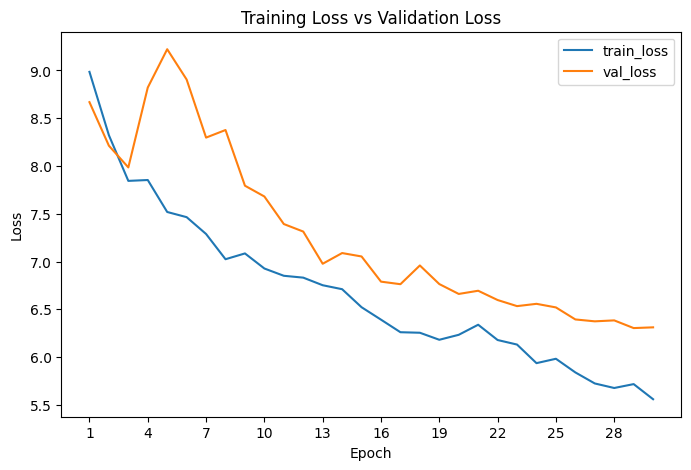

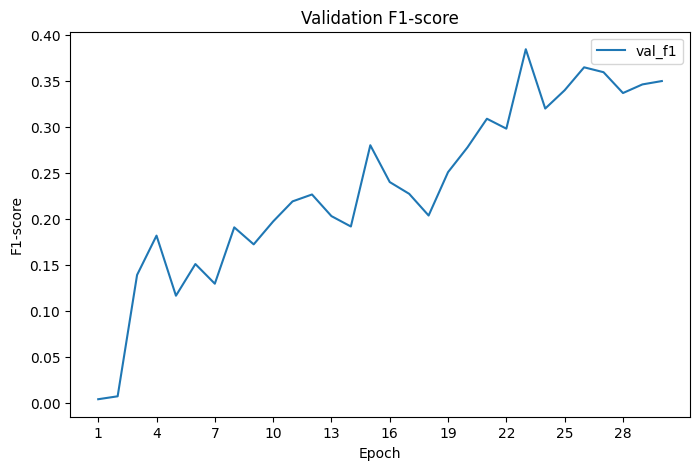

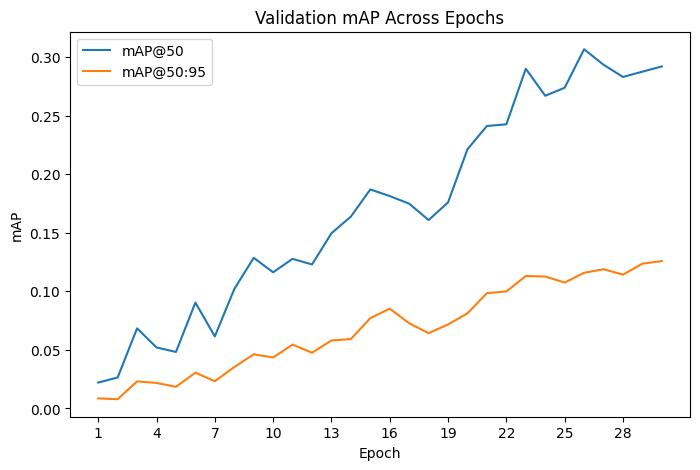

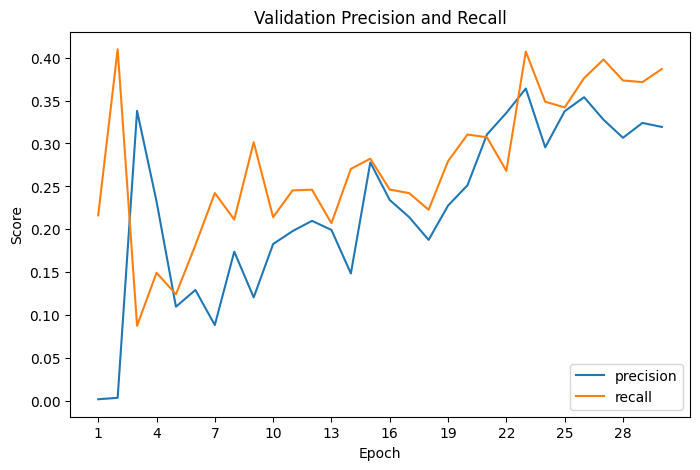

In [17]:
# Load YOLO training results
results_path = Path("runs/detect/train/results.csv")

results_df = pd.read_csv(results_path)
results_df.columns = results_df.columns.str.strip()

epochs = np.arange(1, len(results_df) + 1)

# Total YOLO losses
results_df["train_loss"] = (
    results_df["train/box_loss"] +
    results_df["train/cls_loss"] +
    results_df["train/dfl_loss"]
)

results_df["val_loss"] = (
    results_df["val/box_loss"] +
    results_df["val/cls_loss"] +
    results_df["val/dfl_loss"]
)

# Validation F1-score
results_df["val_f1"] = (
    2 * results_df["metrics/precision(B)"] * results_df["metrics/recall(B)"] /
    (results_df["metrics/precision(B)"] + results_df["metrics/recall(B)"] + 1e-9)
)

print(f"Best validation loss: {results_df['val_loss'].min():.4f}")
print(f"Best validation F1-score: {results_df['val_f1'].max():.4f}")
print(f"Best validation mAP@50: {results_df['metrics/mAP50(B)'].max():.4f}")
print(f"Best validation mAP@50:95: {results_df['metrics/mAP50-95(B)'].max():.4f}")

# 1. Train loss vs validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["train_loss"], label="train_loss")
plt.plot(epochs, results_df["val_loss"], label="val_loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss vs Validation Loss")
plt.xticks(np.arange(1, len(epochs) + 1, 3))
plt.savefig("overfitting_loss_curve.png", bbox_inches="tight")
plt.close()

display(Image(filename="overfitting_loss_curve.png"))

# 2. Validation F1-score
plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["val_f1"], label="val_f1")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("F1-score")
plt.title("Validation F1-score")
plt.xticks(np.arange(1, len(epochs) + 1, 3))
plt.savefig("overfitting_f1_curve.png", bbox_inches="tight")
plt.close()

display(Image(filename="overfitting_f1_curve.png"))

# 3. Validation mAP metrics
plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["metrics/mAP50(B)"], label="mAP@50")
plt.plot(epochs, results_df["metrics/mAP50-95(B)"], label="mAP@50:95")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP Across Epochs")
plt.xticks(np.arange(1, len(epochs) + 1, 3))
plt.savefig("overfitting_map_curve.png", bbox_inches="tight")
plt.close()

display(Image(filename="overfitting_map_curve.png"))

# 4. Validation precision and recall
plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["metrics/precision(B)"], label="precision")
plt.plot(epochs, results_df["metrics/recall(B)"], label="recall")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Precision and Recall")
plt.xticks(np.arange(1, len(epochs) + 1, 3))
plt.savefig("overfitting_precision_recall_curve.png", bbox_inches="tight")
plt.close()

display(Image(filename="overfitting_precision_recall_curve.png"))